# Pelabelan Emosi Menggunakan Lexicon (NRC Emotion Lexicon)

Notebook ini bertujuan untuk memberikan label emosi pada dataset komentar YouTube menggunakan kamus **NRC Emotion Lexicon** versi Bahasa Indonesia.

---

### Alur Proses:
1. **Import Library** - Memuat library yang diperlukan
2. **Load Data** - Membaca file lexicon dan komentar YouTube
3. **Preprocessing** - Membersihkan teks (stopwords, singkatan, dll)
4. **Labeling** - Mencocokkan kata dengan lexicon dan voting emosi
5. **Visualisasi** - WordCloud dan distribusi emosi
6. **Save** - Menyimpan hasil untuk training SVM

In [1]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.1 MB/s eta 0:00:00


---
## Step 1: Import Library

In [2]:
import pandas as pd
import re
import string
import html
import nltk
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn import svm
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

---
## Step 2: Load Data

In [3]:
# Load Lexicon Emosi
lexicon_df = pd.read_csv("indonesian_emotion_lexicon.csv")

print(f"Jumlah kata di Lexicon: {len(lexicon_df)}")
print(f"Kolom Lexicon: {lexicon_df.columns.tolist()}")
print("\nSampel Lexicon:")
lexicon_df.head()

Jumlah kata di Lexicon: 14154
Kolom Lexicon: ['word', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'negative', 'positive', 'sadness', 'surprise', 'trust']

Sampel Lexicon:


,word,anger,anticipation,disgust,fear,joy,negative,positive,sadness,surprise,trust
0,kembali,0,0,0,0,0,0,0,0,0,0
1,sempoa,0,0,0,0,0,0,0,0,0,1
2,meninggalkan,0,0,0,1,0,1,0,1,0,0
3,ditinggalkan,1,0,0,1,0,1,0,1,0,0
4,pengabaian,1,0,0,1,0,1,0,1,1,0


In [4]:
# Load Data Komentar YouTube (SEMUA DATA)
df = pd.read_csv("youtube_comments.csv")

print(f"Jumlah Komentar: {len(df)}")
print(f"Kolom: {df.columns.tolist()}")
df.head()

Jumlah Komentar: 11271
Kolom: ['publishedAt', 'authorDisplayName', 'textDisplay', 'likeCount']


,publishedAt,authorDisplayName,textDisplay,likeCount
0,2025-12-09T02:24:10Z,@Nekokun-k8k,Makasih berkat anda gua jadi bodoh amat kemarin,0
1,2025-12-03T16:05:46Z,@joviputr1238,Anak abah CS DAN BANTENG pasti pada emosi 😅 k...,0
2,2025-11-22T18:29:33Z,@rudiumardani5494,Tau enggak china pki....tai china bangsat....b...,0
3,2025-11-22T18:28:20Z,@rudiumardani5494,Harusnya elu susul tuh si atheis LEE KUAN YEW...,0
4,2025-11-20T03:55:24Z,@Bossge1091,Terlalu banyak otak kosong dan terlalu banyak ...,1


---
## Step 3: Load Stopwords & Singkatan

Sama seperti pada notebook SVM Sentimen.

In [5]:
# Load Stopwords dari NLTK
nltk_stop = set(stopwords.words('indonesian'))

# Load Stoplist lokal
with open('stoplist.txt') as f:
    custom_stop = set([w.strip() for w in f.readlines()])

# Gabungkan semua stopwords
all_stopwords = nltk_stop.union(custom_stop)
print(f"Total Stopwords: {len(all_stopwords)}")

Total Stopwords: 766


In [6]:
# Load Kamus Singkatan
abbr = pd.read_csv('singkatan-lib.csv', header=None, names=['Singkatan', 'Asli'])
abbr_dict = dict(zip(abbr['Singkatan'], abbr['Asli']))

print(f"Total Singkatan: {len(abbr_dict)}")
print("\nContoh Singkatan:")
list(abbr_dict.items())[:5]

Total Singkatan: 175

Contoh Singkatan:


[('aja', 'saja'),
 ('akn', 'akan'),
 ('aku', 'saya'),
 ('amien', 'aamiin'),
 ('amin', 'aamiin')]

---
## Step 4: Preprocessing Data (YouTube Optimized)

Menangani:
- HTML entities (`&amp;`, `<br>`, dll)
- URLs, @mentions, #hashtags
- Emojis
- Karakter berulang (`baguuus` → `bagus`)
- **Singkatan** → Diganti kata asli
- **Stopwords** → Dihapus
- Angka dan tanda baca

In [7]:
def clean_youtube_text(text):
    """Preprocessing khusus untuk komentar YouTube"""
    if not isinstance(text, str):
        return ""

    # 1. Decode HTML entities
    text = html.unescape(text)

    # 2. Hapus HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # 3. Hapus URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 4. Hapus @mentions
    text = re.sub(r'@\w+', '', text)

    # 5. Hapus #hashtags
    text = re.sub(r'#\w+', '', text)

    # 6. Hapus Emojis
    emoji_pattern = re.compile("["
        u"\U0001F600-\U0001F64F"
        u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF"
        u"\U0001F1E0-\U0001F1FF"
        u"\U00002702-\U000027B0"
        u"\U000024C2-\U0001F251"
        u"\U0001f926-\U0001f937"
        u"\U00010000-\U0010ffff"
        "]+", flags=re.UNICODE)
    text = emoji_pattern.sub('', text)

    # 7. Lowercase
    text = text.lower()

    # 8. Normalisasi karakter berulang
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 9. Hapus angka
    text = re.sub(r'\d+', '', text)

    # 10. Hapus tanda baca
    text = text.translate(str.maketrans('', '', string.punctuation))

    # 11. Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [8]:
def preprocess_text(text):
    """Preprocessing lanjutan: Ganti singkatan + Hapus stopwords"""
    tokens = text.split()  # Tokenisasi

    # Ganti Singkatan
    tokens = [abbr_dict.get(tok, tok) for tok in tokens]

    # Hapus Stopwords
    tokens = [tok for tok in tokens if tok not in all_stopwords]

    # Gabungkan kembali
    return ' '.join(tokens)

In [9]:
# Terapkan preprocessing ke kolom textDisplay
df['clean_text'] = df['textDisplay'].apply(clean_youtube_text)
df['clean_text_processed'] = df['clean_text'].apply(preprocess_text)

# Tampilkan hasil
print("Hasil Preprocessing:")
df[['textDisplay', 'clean_text', 'clean_text_processed']].head(10)

Hasil Preprocessing:


,textDisplay,clean_text,clean_text_processed
0,Makasih berkat anda gua jadi bodoh amat kemarin,makasih berkat anda gua jadi bodoh amat kemarin,makasih berkat bodoh kemarin
1,Anak abah CS DAN BANTENG pasti pada emosi 😅 k...,anak abah cs dan banteng pasti pada emosi kare...,anak abah cs banteng emosi rencana gagal
2,Tau enggak china pki....tai china bangsat....b...,tau enggak china pkitai china bangsatbrengsekg...,tau china pkitai china bangsatbrengsekgua tumb...
3,Harusnya elu susul tuh si atheis LEE KUAN YEW...,harusnya elu susul tuh si atheis lee kuan yewb...,elu susul tuh si atheis lee kuan yewbin poorlion
4,Terlalu banyak otak kosong dan terlalu banyak ...,terlalu banyak otak kosong dan terlalu banyak ...,otak kosong penjilat negara apapun bersuara pe...
5,"Bang ferry, gimana reaksi mu dengan ruu kuhp y...",bang ferry gimana reaksi mu dengan ruu kuhp ya...,ferry gimana reaksi mu ruu kuhp disahkan
6,Apakah ada kolerasi denganpengalihan isu ijasah?,apakah ada kolerasi denganpengalihan isu ijasah,kolerasi denganpengalihan isu ijasah
7,Asalamualaikum warohmatulohi wabarakatuh,asalamualaikum warohmatulohi wabarakatuh,asalamualaikum warohmatulohi wabarakatuh
8,Naikin cukai dengan tujuan nurunin pecandu rok...,naikin cukai dengan tujuan nurunin pecandu rok...,naikin cukai tujuan nurunin pecandu rokok pero...
9,Pasti &quot;geter&quot; Mereka melihat video i...,pasti geter mereka melihat video ini,geter video


---
## Step 5: Pelabelan Emosi menggunakan Lexicon

Metode Voting: Mencocokkan kata dengan lexicon dan menghitung skor emosi.

In [10]:
# Buat Dictionary dari Lexicon
lexicon_dict = {}
emotion_cols = ['anger', 'anticipation', 'disgust', 'fear', 'joy', 'negative', 'positive', 'sadness', 'surprise', 'trust']

for _, row in lexicon_df.iterrows():
    word = row['word']
    if pd.notna(word):
        word = str(word).lower().strip()
        lexicon_dict[word] = {col: row[col] for col in emotion_cols}

print(f"Lexicon loaded: {len(lexicon_dict)} kata")
print(f"\nContoh kata di lexicon: {list(lexicon_dict.keys())[:10]}")

Lexicon loaded: 9705 kata

Contoh kata di lexicon: ['kembali', 'sempoa', 'meninggalkan', 'ditinggalkan', 'pengabaian', 'mereda', 'pengurangan', 'abba', 'kepala biara', 'menyingkat']


In [11]:
def get_dominant_emotion(text):
    """Menentukan emosi dominan berdasarkan voting dari lexicon"""
    words = text.split()

    current_scores = {col: 0 for col in emotion_cols}

    found_word = False
    for word in words:
        if word in lexicon_dict:
            found_word = True
            for emotion in emotion_cols:
                current_scores[emotion] += lexicon_dict[word][emotion]

    if not found_word or sum(current_scores.values()) == 0:
        return "neutral"

    # Hanya ambil 8 emosi dasar (Plutchik)
    basic_emotions = ['anger', 'anticipation', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'trust']
    basic_scores = {k: v for k, v in current_scores.items() if k in basic_emotions}

    if sum(basic_scores.values()) == 0:
        return "neutral"

    max_score = max(basic_scores.values())
    top_emotions = [k for k, v in basic_scores.items() if v == max_score]

    return top_emotions[0]

# Terapkan labeling ke clean_text_processed (yang sudah dihapus stopwords)
df['emotion_label'] = df['clean_text_processed'].apply(get_dominant_emotion)

# Tampilkan hasil
print("Hasil Pelabelan Emosi:")
df[['textDisplay', 'clean_text_processed', 'emotion_label']].head(10)

Hasil Pelabelan Emosi:


,textDisplay,clean_text_processed,emotion_label
0,Makasih berkat anda gua jadi bodoh amat kemarin,makasih berkat bodoh kemarin,neutral
1,Anak abah CS DAN BANTENG pasti pada emosi 😅 k...,anak abah cs banteng emosi rencana gagal,anticipation
2,Tau enggak china pki....tai china bangsat....b...,tau china pkitai china bangsatbrengsekgua tumb...,disgust
3,Harusnya elu susul tuh si atheis LEE KUAN YEW...,elu susul tuh si atheis lee kuan yewbin poorlion,neutral
4,Terlalu banyak otak kosong dan terlalu banyak ...,otak kosong penjilat negara apapun bersuara pe...,neutral
5,"Bang ferry, gimana reaksi mu dengan ruu kuhp y...",ferry gimana reaksi mu ruu kuhp disahkan,anger
6,Apakah ada kolerasi denganpengalihan isu ijasah?,kolerasi denganpengalihan isu ijasah,sadness
7,Asalamualaikum warohmatulohi wabarakatuh,asalamualaikum warohmatulohi wabarakatuh,neutral
8,Naikin cukai dengan tujuan nurunin pecandu rok...,naikin cukai tujuan nurunin pecandu rokok pero...,neutral
9,Pasti &quot;geter&quot; Mereka melihat video i...,geter video,neutral


---
## Step 6: Analisis Sebaran Emosi

In [12]:
# Distribusi label emosi
emotion_counts = df['emotion_label'].value_counts()
print("Distribusi Label Emosi:")
print(emotion_counts)

Distribusi Label Emosi:
emotion_label
neutral         5240
anger           1375
trust           1298
fear            1261
anticipation     860
disgust          526
joy              363
sadness          288
surprise          60
Name: count, dtype: int64


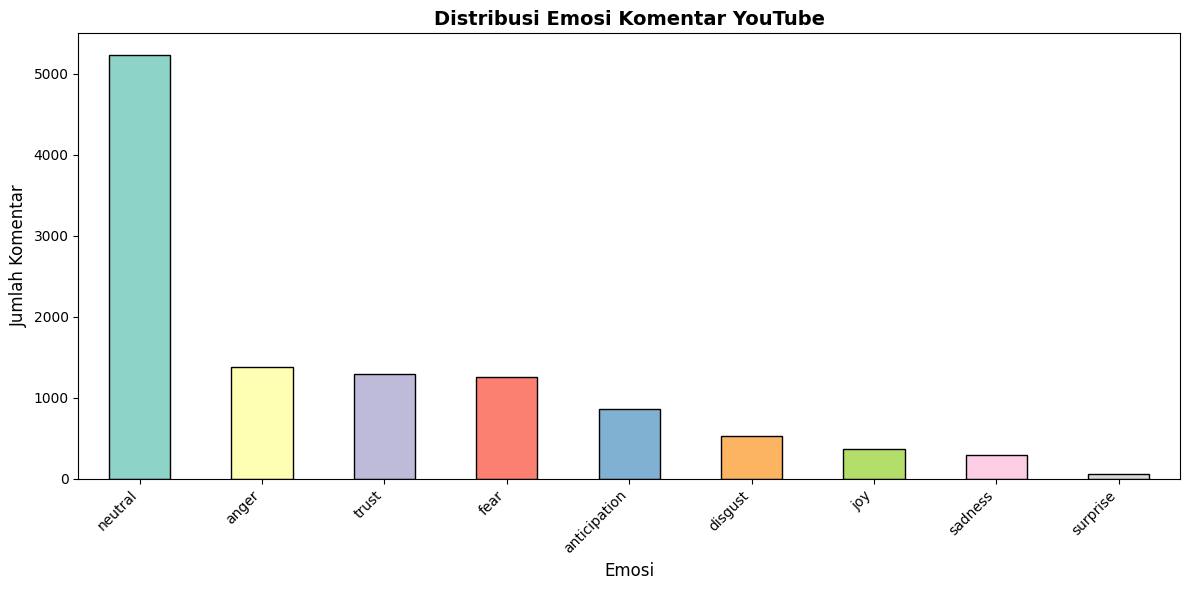

In [13]:
# Visualisasi Bar Chart
plt.figure(figsize=(12, 6))
colors = plt.cm.Set3(range(len(emotion_counts)))
emotion_counts.plot(kind='bar', color=colors, edgecolor='black')
plt.title('Distribusi Emosi Komentar YouTube', fontsize=14, fontweight='bold')
plt.xlabel('Emosi', fontsize=12)
plt.ylabel('Jumlah Komentar', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
## Step 7: Visualisasi WordCloud

In [14]:
def generate_wordcloud(text_series, title):
    """Membuat WordCloud dari series teks"""
    text = " ".join(text_series.dropna().astype(str))

    if len(text.strip()) == 0:
        print(f"Tidak ada data untuk: {title}")
        return

    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        collocations=False,
        max_words=100
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

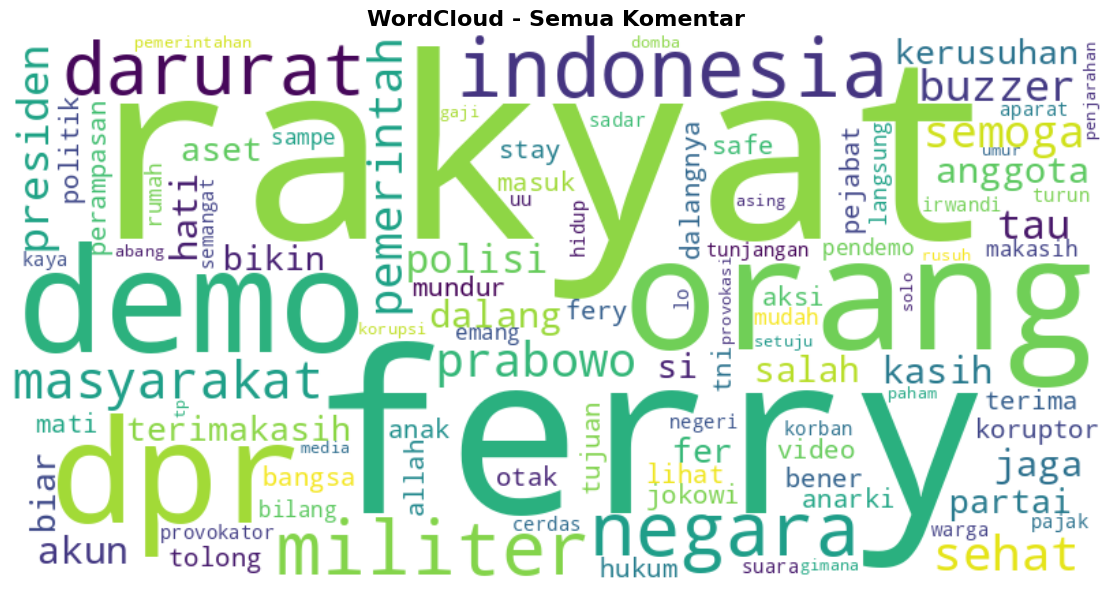

In [15]:
# WordCloud untuk semua komentar (PAKAI clean_text_processed yang sudah dihapus stopwords)
generate_wordcloud(df['clean_text_processed'], 'WordCloud - Semua Komentar')

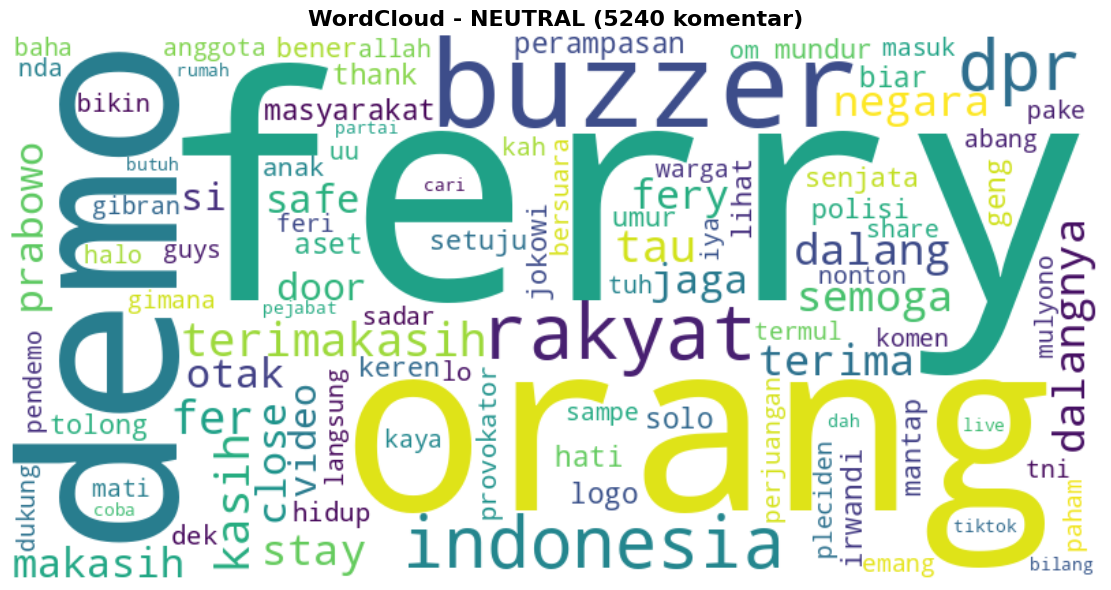

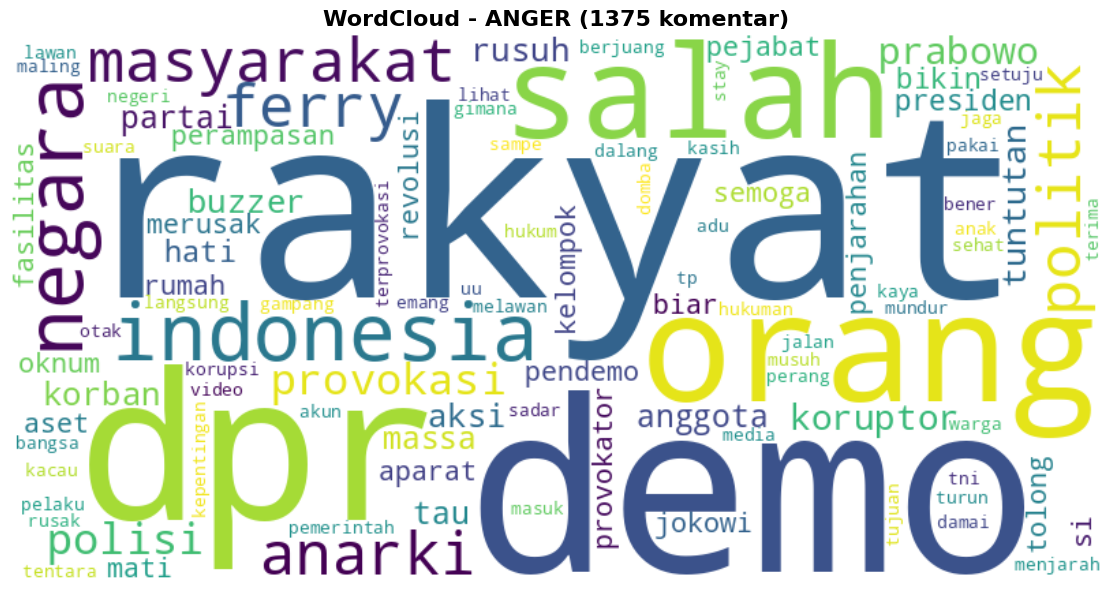

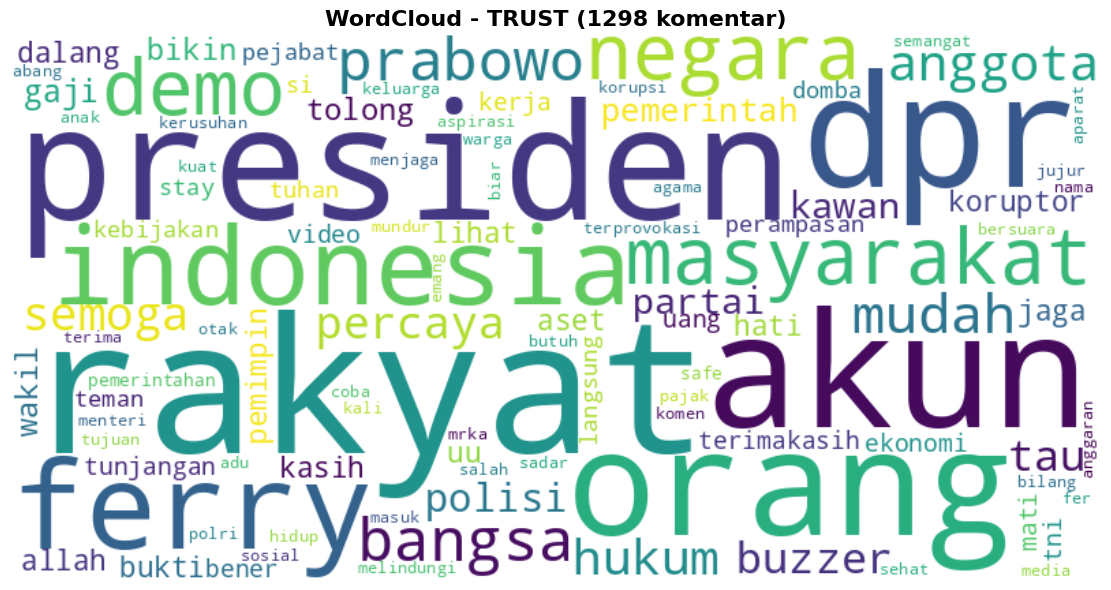

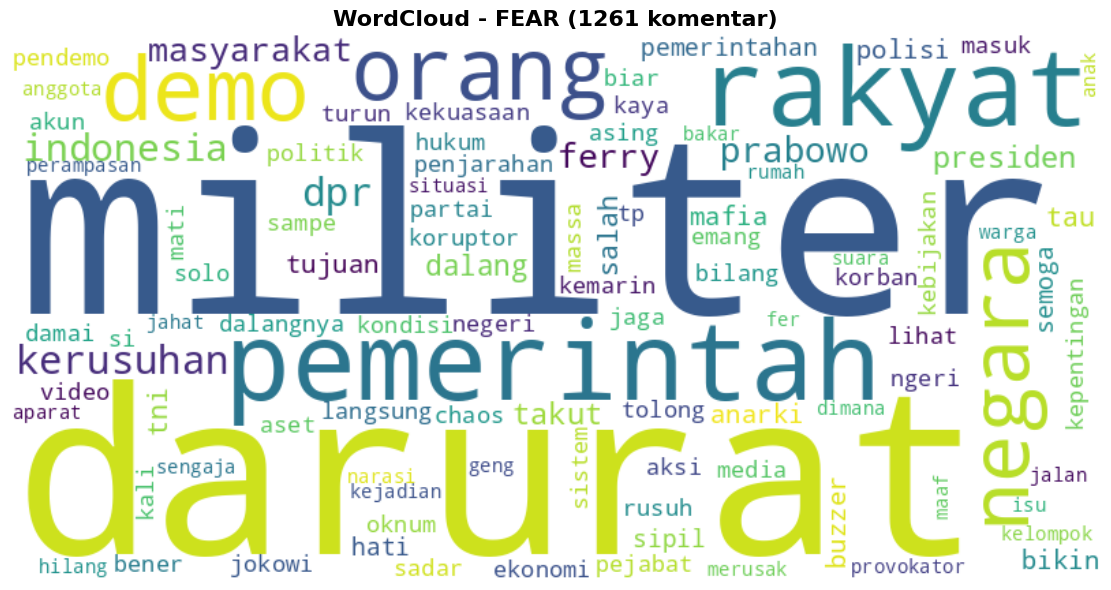

In [16]:
# WordCloud per emosi (untuk 4 emosi teratas)
top_emotions = emotion_counts.head(4).index.tolist()

for emotion in top_emotions:
    subset = df[df['emotion_label'] == emotion]['clean_text_processed']
    if len(subset) > 0:
        generate_wordcloud(subset, f'WordCloud - {emotion.upper()} ({len(subset)} komentar)')

---
## Step 8: Simpan Hasil

Menyimpan dataset yang sudah dilabeli untuk training SVM.

In [17]:
# Simpan ke CSV
output_filename = 'youtube_comment_emotion_labeled.csv'
df.to_csv(output_filename, index=False)

print(f"File berhasil disimpan: {output_filename}")
print(f"Total data: {len(df)} komentar")
print(f"\nDistribusi akhir:")
print(df['emotion_label'].value_counts())

File berhasil disimpan: youtube_comment_emotion_labeled.csv
Total data: 11271 komentar

Distribusi akhir:
emotion_label
neutral         5240
anger           1375
trust           1298
fear            1261
anticipation     860
disgust          526
joy              363
sadness          288
surprise          60
Name: count, dtype: int64
